In [ ]:
import os
import shutil
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')
from scipy.stats import pearsonr
from sklearn.metrics.pairwise import cosine_similarity
import seaborn as sns
import matplotlib.pyplot as plt

from allensdk.brain_observatory.ecephys.ecephys_project_cache import EcephysProjectCache

In [2]:
#path to store the csv
output_dir = "./localstorage/ecephys_cache_dir"


manifest_path = os.path.join(output_dir, "manifest.json")
cache = EcephysProjectCache.from_warehouse(manifest=manifest_path)


#getting all the tables
sessions_df = cache.get_session_table()
probes_df = cache.get_probes()
channels_df = cache.get_channels()
units_df = cache.get_units()

In [3]:
sessions_df.iloc[[24]]

,published_at,specimen_id,session_type,age_in_days,sex,full_genotype,unit_count,channel_count,probe_count,ecephys_structure_acronyms
id,,,,,,,,,,
762120172,2019-10-03T00:00:00Z,745276236,brain_observatory_1.1,100.0,M,Vip-IRES-Cre/wt;Ai32(RCL-ChR2(H134R)_EYFP)/wt,717,1860,5,"[grey, VISal, nan, VISl, VISp, VIS, VISam]"


In [4]:
#finally got it to downloadd
session = cache.get_session_data(
    sessions_df.index.values[24],
    isi_violations_maximum = float('inf'),
    amplitude_cutoff_maximum = float('inf'),
    presence_ratio_minimum = -float('inf')
)

print(f"Session {sessions_df.index.values[24]} loaded successfully!")
print(f"Total units (neurons): {len(session.units)}")

Session 762120172 loaded successfully!
Total units (neurons): 1642


In [5]:
drifting_table = session.stimulus_presentations[session.stimulus_presentations.stimulus_name == "drifting_gratings"]

len(drifting_table)

630

In [6]:
drifting_table

,stimulus_block,start_time,stop_time,temporal_frequency,contrast,stimulus_name,orientation,spatial_frequency,y_position,size,color,frame,phase,x_position,duration,stimulus_condition_id
stimulus_presentation_id,,,,,,,,,,,,,,,,
3798,2.0,1592.948984,1594.950644,1.0,0.8,drifting_gratings,225.0,0.04,null,"[250.0, 250.0]",null,null,"[79634.75, 79634.75]",null,2.00166,246
3799,2.0,1595.951487,1597.953167,2.0,0.8,drifting_gratings,135.0,0.04,null,"[250.0, 250.0]",null,null,"[79634.75, 79634.75]",null,2.00168,247
3800,2.0,1598.954004,1600.955644,15.0,0.8,drifting_gratings,225.0,0.04,null,"[250.0, 250.0]",null,null,"[79634.75, 79634.75]",null,2.00164,248
3801,2.0,1601.956507,1603.958177,2.0,0.8,drifting_gratings,45.0,0.04,null,"[250.0, 250.0]",null,null,"[79634.75, 79634.75]",null,2.00167,249
3802,2.0,1604.959034,1606.960684,2.0,0.8,drifting_gratings,135.0,0.04,null,"[250.0, 250.0]",null,null,"[79634.75, 79634.75]",null,2.00165,247
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49428,7.0,5391.122617,5393.124297,8.0,0.8,drifting_gratings,45.0,0.04,null,"[250.0, 250.0]",null,null,"[79634.75, 79634.75]",null,2.00168,265
49429,7.0,5394.125144,5396.126794,8.0,0.8,drifting_gratings,270.0,0.04,null,"[250.0, 250.0]",null,null,"[79634.75, 79634.75]",null,2.00165,285
49430,7.0,5397.127637,5399.129317,2.0,0.8,drifting_gratings,180.0,0.04,null,"[250.0, 250.0]",null,null,"[79634.75, 79634.75]",null,2.00168,281


In [7]:
visp_unit = session.units[session.units["ecephys_structure_acronym"].isin(["VISp"])
                              & (session.units.isi_violations < 0.5)
                               & (session.units.amplitude_cutoff < 0.1)
                               & (session.units.presence_ratio > 0.9)]

visp_unit

,waveform_PT_ratio,waveform_amplitude,amplitude_cutoff,cluster_id,cumulative_drift,d_prime,firing_rate,isi_violations,isolation_distance,L_ratio,...,ecephys_structure_id,ecephys_structure_acronym,anterior_posterior_ccf_coordinate,dorsal_ventral_ccf_coordinate,left_right_ccf_coordinate,probe_description,location,probe_sampling_rate,probe_lfp_sampling_rate,probe_has_lfp_data
unit_id,,,,,,,,,,,,,,,,,,,,,
951869857,0.599222,159.99672,0.002672,295,190.03,2.121158,0.837062,0.417065,39.174680,0.013506,...,385.0,VISp,NaN,NaN,NaN,probeC,See electrode locations,29999.995019,1249.999792,True
951869927,0.461788,91.14807,0.039226,300,313.01,2.176517,3.038721,0.336253,33.318748,0.068869,...,385.0,VISp,NaN,NaN,NaN,probeC,See electrode locations,29999.995019,1249.999792,True
951869889,0.372887,93.63939,0.026483,297,171.00,2.534168,5.747939,0.148153,55.853066,0.015258,...,385.0,VISp,NaN,NaN,NaN,probeC,See electrode locations,29999.995019,1249.999792,True
951870013,0.387984,164.03283,0.001337,306,57.83,4.560852,1.347251,0.000000,68.793003,0.000504,...,385.0,VISp,NaN,NaN,NaN,probeC,See electrode locations,29999.995019,1249.999792,True
951869958,0.504386,113.29227,0.074867,302,127.44,3.361614,0.380084,0.000000,23.934092,0.029283,...,385.0,VISp,NaN,NaN,NaN,probeC,See electrode locations,29999.995019,1249.999792,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
951872625,0.431735,173.48955,0.001993,470,132.58,5.214571,1.494996,0.081718,57.911138,0.002113,...,385.0,VISp,NaN,NaN,NaN,probeC,See electrode locations,29999.995019,1249.999792,True
951872791,0.566744,107.32995,0.018432,479,199.34,3.658216,1.146196,0.222434,49.934805,0.008267,...,385.0,VISp,NaN,NaN,NaN,probeC,See electrode locations,29999.995019,1249.999792,True
951872885,0.354377,167.96442,0.000409,484,125.99,6.232315,2.649672,0.254942,79.584944,0.001523,...,385.0,VISp,NaN,NaN,NaN,probeC,See electrode locations,29999.995019,1249.999792,True


In [8]:
visp_spike_counts = session.presentationwise_spike_counts(
    bin_edges=[0,2.0],
    stimulus_presentation_ids=drifting_table.index,
    unit_ids=visp_unit.index
)

visp_spike_counts = visp_spike_counts.to_dataframe().reset_index()

visp_spike_counts

,stimulus_presentation_id,time_relative_to_stimulus_onset,unit_id,spike_counts
0,3798,1.0,951869857,0
1,3798,1.0,951869927,35
2,3798,1.0,951869889,5
3,3798,1.0,951870013,0
4,3798,1.0,951869958,0
...,...,...,...,...
55435,49432,1.0,951872625,0
55436,49432,1.0,951872791,0
55437,49432,1.0,951872885,3
55438,49432,1.0,951873010,0


In [9]:
visal_unit = session.units[session.units["ecephys_structure_acronym"].isin(["VISal"])
                              & (session.units.isi_violations < 0.5)
                               & (session.units.amplitude_cutoff < 0.1)
                               & (session.units.presence_ratio > 0.9)]

visal_unit

,waveform_PT_ratio,waveform_amplitude,amplitude_cutoff,cluster_id,cumulative_drift,d_prime,firing_rate,isi_violations,isolation_distance,L_ratio,...,ecephys_structure_id,ecephys_structure_acronym,anterior_posterior_ccf_coordinate,dorsal_ventral_ccf_coordinate,left_right_ccf_coordinate,probe_description,location,probe_sampling_rate,probe_lfp_sampling_rate,probe_has_lfp_data
unit_id,,,,,,,,,,,,,,,,,,,,,
951889708,0.870195,209.393730,0.003331,612,43.48,5.120029,1.254677,0.092817,55.210212,3.353447e-03,...,402.0,VISal,NaN,NaN,NaN,probeE,See electrode locations,29999.998169,1249.999924,True
951887392,0.529151,115.705590,0.002158,419,179.19,3.885530,1.428153,0.017909,47.156678,8.529431e-03,...,402.0,VISal,NaN,NaN,NaN,probeE,See electrode locations,29999.998169,1249.999924,True
951887324,0.335879,79.409070,0.020248,415,204.16,2.924791,3.926981,0.004737,58.223501,9.940287e-03,...,402.0,VISal,NaN,NaN,NaN,probeE,See electrode locations,29999.998169,1249.999924,True
951889715,0.332777,127.850775,0.000526,613,162.76,3.697791,1.657861,0.053161,50.061403,6.723407e-03,...,402.0,VISal,NaN,NaN,NaN,probeE,See electrode locations,29999.998169,1249.999924,True
951887374,0.222203,200.956080,0.000007,418,50.20,6.371321,3.856031,0.000000,141.257016,1.520508e-08,...,402.0,VISal,NaN,NaN,NaN,probeE,See electrode locations,29999.998169,1249.999924,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
951889319,0.431882,81.616275,0.034704,570,368.91,4.046656,2.175559,0.285557,47.499341,1.209397e-02,...,402.0,VISal,NaN,NaN,NaN,probeE,See electrode locations,29999.998169,1249.999924,True
951889393,0.859154,67.670265,0.033603,577,173.22,3.942161,7.567629,0.045287,62.736802,1.331759e-02,...,402.0,VISal,NaN,NaN,NaN,probeE,See electrode locations,29999.998169,1249.999924,True
951889414,0.505753,138.242520,0.002503,579,370.05,5.247800,1.792841,0.318205,60.791003,4.210601e-03,...,402.0,VISal,NaN,NaN,NaN,probeE,See electrode locations,29999.998169,1249.999924,True


In [10]:
visal_spike_counts = session.presentationwise_spike_counts(
    bin_edges=[0,2.0],
    stimulus_presentation_ids=drifting_table.index,
    unit_ids=visal_unit.index
)

visal_spike_counts = visal_spike_counts.to_dataframe().reset_index()

visal_spike_counts

,stimulus_presentation_id,time_relative_to_stimulus_onset,unit_id,spike_counts
0,3798,1.0,951889708,14
1,3798,1.0,951887392,0
2,3798,1.0,951887324,3
3,3798,1.0,951889715,0
4,3798,1.0,951887374,18
...,...,...,...,...
58585,49432,1.0,951889319,1
58586,49432,1.0,951889393,37
58587,49432,1.0,951889414,3
58588,49432,1.0,951889404,1


In [11]:
visp_spike_counts = visp_spike_counts.merge(
    visp_unit[['ecephys_structure_acronym']], 
    left_on='unit_id', 
    right_index=True
)

visp_spike_counts

,stimulus_presentation_id,time_relative_to_stimulus_onset,unit_id,spike_counts,ecephys_structure_acronym
0,3798,1.0,951869857,0,VISp
88,3799,1.0,951869857,0,VISp
176,3800,1.0,951869857,1,VISp
264,3801,1.0,951869857,0,VISp
352,3802,1.0,951869857,0,VISp
...,...,...,...,...,...
55087,49428,1.0,951873128,1,VISp
55175,49429,1.0,951873128,0,VISp
55263,49430,1.0,951873128,0,VISp
55351,49431,1.0,951873128,0,VISp


In [12]:
visal_spike_counts = visal_spike_counts.merge(
    visal_unit[['ecephys_structure_acronym']], 
    left_on='unit_id', 
    right_index=True
)

visal_spike_counts

,stimulus_presentation_id,time_relative_to_stimulus_onset,unit_id,spike_counts,ecephys_structure_acronym
0,3798,1.0,951889708,14,VISal
93,3799,1.0,951889708,21,VISal
186,3800,1.0,951889708,25,VISal
279,3801,1.0,951889708,15,VISal
372,3802,1.0,951889708,14,VISal
...,...,...,...,...,...
58217,49428,1.0,951889441,7,VISal
58310,49429,1.0,951889441,8,VISal
58403,49430,1.0,951889441,10,VISal
58496,49431,1.0,951889441,3,VISal


In [13]:
visp_spike_counts = pd.merge(visp_spike_counts, drifting_table, left_on="stimulus_presentation_id", right_index=True)
visp_spike_counts

,stimulus_presentation_id,time_relative_to_stimulus_onset,unit_id,spike_counts,ecephys_structure_acronym,stimulus_block,start_time,stop_time,temporal_frequency,contrast,...,orientation,spatial_frequency,y_position,size,color,frame,phase,x_position,duration,stimulus_condition_id
0,3798,1.0,951869857,0,VISp,2.0,1592.948984,1594.950644,1.0,0.8,...,225.0,0.04,null,"[250.0, 250.0]",null,null,"[79634.75, 79634.75]",null,2.00166,246
1,3798,1.0,951869927,35,VISp,2.0,1592.948984,1594.950644,1.0,0.8,...,225.0,0.04,null,"[250.0, 250.0]",null,null,"[79634.75, 79634.75]",null,2.00166,246
2,3798,1.0,951869889,5,VISp,2.0,1592.948984,1594.950644,1.0,0.8,...,225.0,0.04,null,"[250.0, 250.0]",null,null,"[79634.75, 79634.75]",null,2.00166,246
3,3798,1.0,951870013,0,VISp,2.0,1592.948984,1594.950644,1.0,0.8,...,225.0,0.04,null,"[250.0, 250.0]",null,null,"[79634.75, 79634.75]",null,2.00166,246
4,3798,1.0,951869958,0,VISp,2.0,1592.948984,1594.950644,1.0,0.8,...,225.0,0.04,null,"[250.0, 250.0]",null,null,"[79634.75, 79634.75]",null,2.00166,246
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
55435,49432,1.0,951872625,0,VISp,7.0,5403.132657,5405.134317,15.0,0.8,...,135.0,0.04,null,"[250.0, 250.0]",null,null,"[79634.75, 79634.75]",null,2.00166,253
55436,49432,1.0,951872791,0,VISp,7.0,5403.132657,5405.134317,15.0,0.8,...,135.0,0.04,null,"[250.0, 250.0]",null,null,"[79634.75, 79634.75]",null,2.00166,253
55437,49432,1.0,951872885,3,VISp,7.0,5403.132657,5405.134317,15.0,0.8,...,135.0,0.04,null,"[250.0, 250.0]",null,null,"[79634.75, 79634.75]",null,2.00166,253
55438,49432,1.0,951873010,0,VISp,7.0,5403.132657,5405.134317,15.0,0.8,...,135.0,0.04,null,"[250.0, 250.0]",null,null,"[79634.75, 79634.75]",null,2.00166,253


In [14]:
visal_spike_counts = pd.merge(visal_spike_counts, drifting_table, left_on="stimulus_presentation_id", right_index=True)
visal_spike_counts

,stimulus_presentation_id,time_relative_to_stimulus_onset,unit_id,spike_counts,ecephys_structure_acronym,stimulus_block,start_time,stop_time,temporal_frequency,contrast,...,orientation,spatial_frequency,y_position,size,color,frame,phase,x_position,duration,stimulus_condition_id
0,3798,1.0,951889708,14,VISal,2.0,1592.948984,1594.950644,1.0,0.8,...,225.0,0.04,null,"[250.0, 250.0]",null,null,"[79634.75, 79634.75]",null,2.00166,246
1,3798,1.0,951887392,0,VISal,2.0,1592.948984,1594.950644,1.0,0.8,...,225.0,0.04,null,"[250.0, 250.0]",null,null,"[79634.75, 79634.75]",null,2.00166,246
2,3798,1.0,951887324,3,VISal,2.0,1592.948984,1594.950644,1.0,0.8,...,225.0,0.04,null,"[250.0, 250.0]",null,null,"[79634.75, 79634.75]",null,2.00166,246
3,3798,1.0,951889715,0,VISal,2.0,1592.948984,1594.950644,1.0,0.8,...,225.0,0.04,null,"[250.0, 250.0]",null,null,"[79634.75, 79634.75]",null,2.00166,246
4,3798,1.0,951887374,18,VISal,2.0,1592.948984,1594.950644,1.0,0.8,...,225.0,0.04,null,"[250.0, 250.0]",null,null,"[79634.75, 79634.75]",null,2.00166,246
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58585,49432,1.0,951889319,1,VISal,7.0,5403.132657,5405.134317,15.0,0.8,...,135.0,0.04,null,"[250.0, 250.0]",null,null,"[79634.75, 79634.75]",null,2.00166,253
58586,49432,1.0,951889393,37,VISal,7.0,5403.132657,5405.134317,15.0,0.8,...,135.0,0.04,null,"[250.0, 250.0]",null,null,"[79634.75, 79634.75]",null,2.00166,253
58587,49432,1.0,951889414,3,VISal,7.0,5403.132657,5405.134317,15.0,0.8,...,135.0,0.04,null,"[250.0, 250.0]",null,null,"[79634.75, 79634.75]",null,2.00166,253
58588,49432,1.0,951889404,1,VISal,7.0,5403.132657,5405.134317,15.0,0.8,...,135.0,0.04,null,"[250.0, 250.0]",null,null,"[79634.75, 79634.75]",null,2.00166,253


In [15]:
visp_spike_counts['firing_rate_hz'] = visp_spike_counts['spike_counts'] / (visp_spike_counts["stop_time"] - visp_spike_counts["start_time"])

visp_spike_counts

,stimulus_presentation_id,time_relative_to_stimulus_onset,unit_id,spike_counts,ecephys_structure_acronym,stimulus_block,start_time,stop_time,temporal_frequency,contrast,...,spatial_frequency,y_position,size,color,frame,phase,x_position,duration,stimulus_condition_id,firing_rate_hz
0,3798,1.0,951869857,0,VISp,2.0,1592.948984,1594.950644,1.0,0.8,...,0.04,null,"[250.0, 250.0]",null,null,"[79634.75, 79634.75]",null,2.00166,246,0.000000
1,3798,1.0,951869927,35,VISp,2.0,1592.948984,1594.950644,1.0,0.8,...,0.04,null,"[250.0, 250.0]",null,null,"[79634.75, 79634.75]",null,2.00166,246,17.485487
2,3798,1.0,951869889,5,VISp,2.0,1592.948984,1594.950644,1.0,0.8,...,0.04,null,"[250.0, 250.0]",null,null,"[79634.75, 79634.75]",null,2.00166,246,2.497927
3,3798,1.0,951870013,0,VISp,2.0,1592.948984,1594.950644,1.0,0.8,...,0.04,null,"[250.0, 250.0]",null,null,"[79634.75, 79634.75]",null,2.00166,246,0.000000
4,3798,1.0,951869958,0,VISp,2.0,1592.948984,1594.950644,1.0,0.8,...,0.04,null,"[250.0, 250.0]",null,null,"[79634.75, 79634.75]",null,2.00166,246,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
55435,49432,1.0,951872625,0,VISp,7.0,5403.132657,5405.134317,15.0,0.8,...,0.04,null,"[250.0, 250.0]",null,null,"[79634.75, 79634.75]",null,2.00166,253,0.000000
55436,49432,1.0,951872791,0,VISp,7.0,5403.132657,5405.134317,15.0,0.8,...,0.04,null,"[250.0, 250.0]",null,null,"[79634.75, 79634.75]",null,2.00166,253,0.000000
55437,49432,1.0,951872885,3,VISp,7.0,5403.132657,5405.134317,15.0,0.8,...,0.04,null,"[250.0, 250.0]",null,null,"[79634.75, 79634.75]",null,2.00166,253,1.498756
55438,49432,1.0,951873010,0,VISp,7.0,5403.132657,5405.134317,15.0,0.8,...,0.04,null,"[250.0, 250.0]",null,null,"[79634.75, 79634.75]",null,2.00166,253,0.000000


In [16]:
visal_spike_counts['firing_rate_hz'] = visal_spike_counts['spike_counts'] / (visal_spike_counts["stop_time"] - visal_spike_counts["start_time"])

visal_spike_counts

,stimulus_presentation_id,time_relative_to_stimulus_onset,unit_id,spike_counts,ecephys_structure_acronym,stimulus_block,start_time,stop_time,temporal_frequency,contrast,...,spatial_frequency,y_position,size,color,frame,phase,x_position,duration,stimulus_condition_id,firing_rate_hz
0,3798,1.0,951889708,14,VISal,2.0,1592.948984,1594.950644,1.0,0.8,...,0.04,null,"[250.0, 250.0]",null,null,"[79634.75, 79634.75]",null,2.00166,246,6.994195
1,3798,1.0,951887392,0,VISal,2.0,1592.948984,1594.950644,1.0,0.8,...,0.04,null,"[250.0, 250.0]",null,null,"[79634.75, 79634.75]",null,2.00166,246,0.000000
2,3798,1.0,951887324,3,VISal,2.0,1592.948984,1594.950644,1.0,0.8,...,0.04,null,"[250.0, 250.0]",null,null,"[79634.75, 79634.75]",null,2.00166,246,1.498756
3,3798,1.0,951889715,0,VISal,2.0,1592.948984,1594.950644,1.0,0.8,...,0.04,null,"[250.0, 250.0]",null,null,"[79634.75, 79634.75]",null,2.00166,246,0.000000
4,3798,1.0,951887374,18,VISal,2.0,1592.948984,1594.950644,1.0,0.8,...,0.04,null,"[250.0, 250.0]",null,null,"[79634.75, 79634.75]",null,2.00166,246,8.992536
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58585,49432,1.0,951889319,1,VISal,7.0,5403.132657,5405.134317,15.0,0.8,...,0.04,null,"[250.0, 250.0]",null,null,"[79634.75, 79634.75]",null,2.00166,253,0.499585
58586,49432,1.0,951889393,37,VISal,7.0,5403.132657,5405.134317,15.0,0.8,...,0.04,null,"[250.0, 250.0]",null,null,"[79634.75, 79634.75]",null,2.00166,253,18.484658
58587,49432,1.0,951889414,3,VISal,7.0,5403.132657,5405.134317,15.0,0.8,...,0.04,null,"[250.0, 250.0]",null,null,"[79634.75, 79634.75]",null,2.00166,253,1.498756
58588,49432,1.0,951889404,1,VISal,7.0,5403.132657,5405.134317,15.0,0.8,...,0.04,null,"[250.0, 250.0]",null,null,"[79634.75, 79634.75]",null,2.00166,253,0.499585


In [17]:
clean_visp = visp_spike_counts[visp_spike_counts["orientation"] != "null"].copy()
clean_visal = visal_spike_counts[visal_spike_counts["orientation"] != "null"].copy()

x_df1 = clean_visp.pivot_table(
    index="stimulus_presentation_id",
    columns="unit_id",
    values="firing_rate_hz",
    fill_value=0.0
)

x_df2 = clean_visal.pivot_table(
    index="stimulus_presentation_id",
    columns="unit_id",
    values="firing_rate_hz",
    fill_value=0.0
)

y_visp = clean_visp.groupby("stimulus_presentation_id")["orientation"].first().loc[x_df1.index].values
y_visal = clean_visal.groupby("stimulus_presentation_id")["orientation"].first().loc[x_df2.index].values

unique_orientations = np.sort(np.unique(y_visp))

In [18]:
x_df1

unit_id,951869857,951869889,951869927,951869958,951870013,951870077,951870091,951870106,951870204,951870230,...,951873128,951874045,951874082,951874122,951874133,951874148,951874163,951874454,951874473,951874527
stimulus_presentation_id,,,,,,,,,,,,,,,,,,,,,
3798,0.00000,2.497927,17.485487,0.000000,0.000000,0.000000,1.498756,0.499585,32.972633,24.479682,...,0.000000,0.499585,0.000000,0.999171,1.498756,0.000000,0.000000,2.997512,1.498756,0.000000
3799,0.00000,3.497062,8.492866,0.000000,0.000000,0.000000,7.993286,0.000000,31.473562,43.963071,...,0.000000,6.494545,1.498741,0.499580,0.000000,0.499580,0.000000,0.999161,0.999161,10.990768
3800,0.49959,0.000000,10.491397,0.000000,0.000000,0.499590,0.000000,0.000000,47.461082,19.983613,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.497952,1.498771,0.000000
3801,0.00000,1.498749,20.982480,0.000000,0.000000,0.000000,3.497080,0.000000,41.465376,24.479560,...,0.499583,0.000000,0.000000,0.499583,0.499583,0.000000,0.499583,1.998331,4.995828,0.999166
3802,0.00000,0.000000,7.993405,0.000000,0.000000,0.000000,12.489696,0.499588,29.975270,25.478980,...,0.000000,3.497115,0.499588,0.000000,0.000000,0.000000,0.000000,1.998351,0.999176,1.498764
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49428,0.00000,0.000000,2.497902,0.000000,0.000000,0.999161,19.483634,0.000000,31.973143,3.996643,...,0.499580,0.000000,0.999161,0.000000,1.998321,0.499580,0.000000,1.998321,0.999161,0.000000
49429,0.00000,3.996703,0.999176,0.999176,0.000000,0.999176,23.480628,11.490520,37.469088,0.999176,...,0.000000,0.000000,0.999176,0.000000,1.498764,0.000000,0.999176,2.497939,4.496291,0.499588
49430,0.00000,0.499580,4.995804,0.000000,1.498741,0.499580,9.492027,0.000000,20.482794,5.994964,...,0.000000,8.992446,2.497902,0.000000,0.999161,0.000000,0.000000,2.497902,2.497902,1.998321


In [19]:
x_df2

unit_id,951887324,951887343,951887374,951887392,951887446,951887459,951887488,951887525,951887578,951887611,...,951889794,951889825,951889841,951889854,951889863,951889883,951889909,951889926,951890060,951890069
stimulus_presentation_id,,,,,,,,,,,,,,,,,,,,,
3798,1.498756,19.483828,8.992536,0.000000,0.000000,2.497927,0.000000,0.0,8.992536,0.0,...,0.000000,0.000000,4.496268,0.999171,1.998341,0.499585,0.0,0.000000,3.996683,0.00000
3799,3.497062,15.986571,7.493705,0.999161,0.000000,1.498741,0.000000,0.0,11.490348,0.0,...,0.000000,6.494545,0.999161,2.997482,0.000000,3.996643,0.0,0.000000,4.496223,0.00000
3800,3.497132,13.488939,9.492216,11.990168,0.000000,7.993445,0.000000,0.0,8.992626,0.0,...,0.000000,0.999181,1.998361,8.493036,0.000000,0.999181,0.0,0.000000,0.999181,0.00000
3801,3.497080,13.988320,8.992491,0.499583,0.000000,6.994160,0.000000,0.0,13.488737,0.0,...,0.499583,1.498749,3.497080,4.995828,0.000000,3.497080,0.0,0.499583,3.996663,0.00000
3802,5.995054,12.489696,6.994230,0.000000,0.000000,0.000000,0.000000,0.0,8.492993,0.0,...,0.499588,4.995878,12.989284,6.494642,0.499588,1.498764,0.0,0.499588,1.498764,0.00000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49428,3.996643,2.997482,0.499580,3.497062,2.997482,3.497062,2.497902,0.0,0.000000,0.0,...,0.000000,0.000000,0.499580,1.498741,0.499580,0.000000,0.0,1.998321,1.498741,0.49958
49429,2.497939,5.995054,0.499588,0.499588,5.995054,4.995878,3.996703,0.0,0.499588,0.0,...,0.499588,3.996703,4.995878,3.497115,1.498764,1.498764,0.0,0.000000,0.000000,0.00000
49430,3.996643,15.486991,1.498741,0.000000,0.000000,4.496223,1.498741,0.0,1.498741,0.0,...,2.497902,2.997482,1.998321,0.000000,0.000000,0.999161,0.0,2.497902,2.497902,0.00000


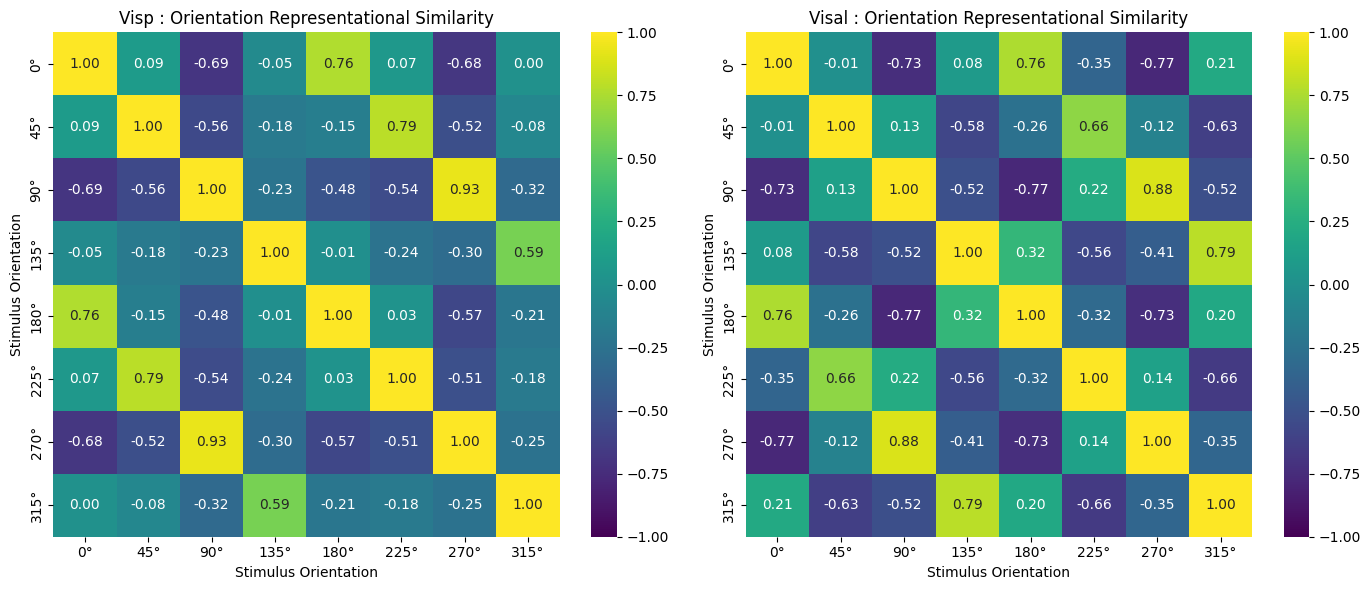

In [ ]:
x_df1_centered = x_df1 - x_df1.mean(axis=0)
x_df2_centered = x_df2 - x_df2.mean(axis=0)

visp_pop_vectors = np.array([x_df1_centered[y_visp == ori].mean(axis=0) for ori in unique_orientations])
visal_pop_vectors = np.array([x_df2_centered[y_visal == ori].mean(axis=0) for ori in unique_orientations])

visp_cos_sim = cosine_similarity(visp_pop_vectors)
visal_cos_sim = cosine_similarity(visal_pop_vectors)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
ori_labels = [f"{int(o)}°" for o in unique_orientations]

sns.heatmap(
    visp_cos_sim, ax=axes[0], annot=True, fmt=".2f", cmap="viridis", 
    vmin=-1, vmax=1, xticklabels=ori_labels, yticklabels=ori_labels
)
axes[0].set_title("Visp : Orientation Representational Similarity")
axes[0].set_xlabel("Stimulus Orientation")
axes[0].set_ylabel("Stimulus Orientation")

sns.heatmap(
    visal_cos_sim, ax=axes[1], annot=True, fmt=".2f", cmap="viridis", 
    vmin=-1, vmax=1, xticklabels=ori_labels, yticklabels=ori_labels
)
axes[1].set_title("Visal : Orientation Representational Similarity")
axes[1].set_xlabel("Stimulus Orientation")
axes[1].set_ylabel("Stimulus Orientation")

plt.tight_layout()
plt.show()


In [21]:
def linear_cka(X, Y):
    X = X - X.mean(axis=0, keepdims=True)
    Y = Y - Y.mean(axis=0, keepdims=True)

    numerator = np.linalg.norm(np.dot(Y.T, X), 'fro') ** 2
    denominator = np.linalg.norm(np.dot(X.T, X), 'fro') * np.linalg.norm(np.dot(Y.T, Y), 'fro')
    
    return numerator / (denominator + 1e-10)

observed_cka = linear_cka(visp_pop_vectors, visal_pop_vectors)
print(f"Observed CKA Similarity: {observed_cka:.4f}")

n_permutations = 1000
permuted_cka = np.zeros(n_permutations)

for i in range(n_permutations):
    visal_permuted = np.random.permutation(visal_pop_vectors.T).T
    permuted_cka[i] = linear_cka(visp_pop_vectors, visal_permuted)

p_value = np.sum(permuted_cka >= observed_cka) / n_permutations

print(f"Permutation Test p-value: {p_value:.4f}")
print(f"Chance CKA (Mean ± SD): {np.mean(permuted_cka):.4f} ± {np.std(permuted_cka):.4f}")


Observed CKA Similarity: 0.8316
Permutation Test p-value: 0.9050
Chance CKA (Mean ± SD): 0.8316 ± 0.0000


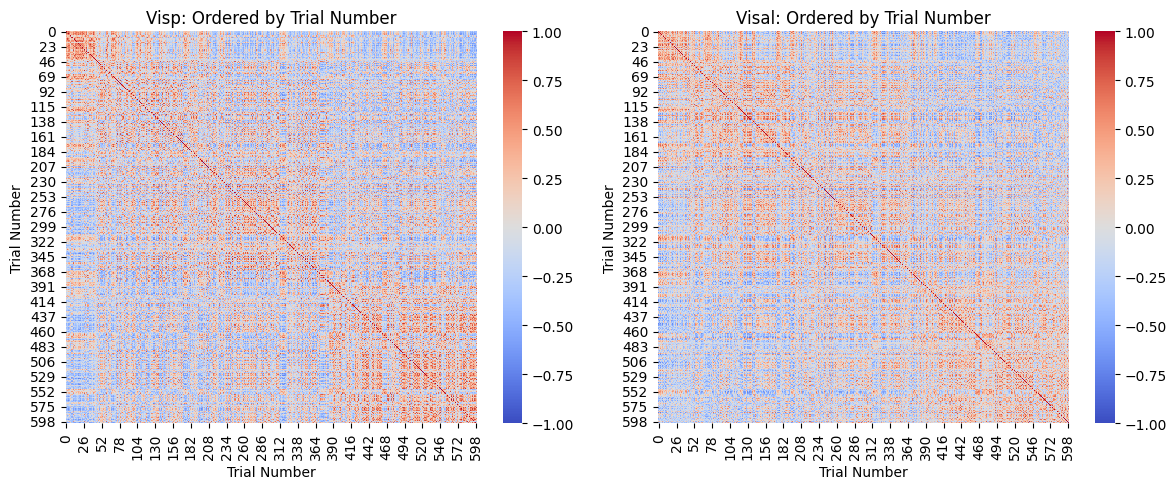

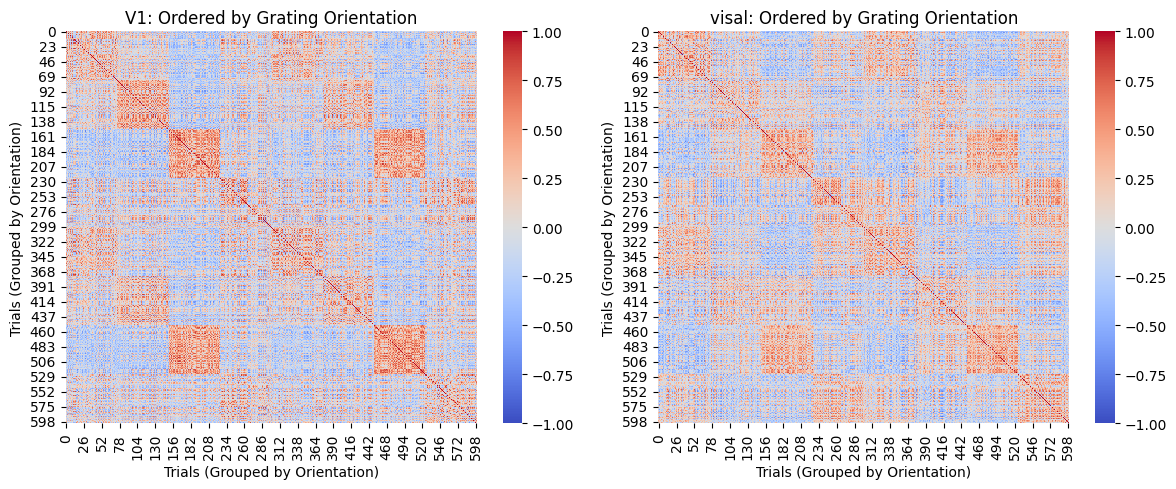

In [24]:
x_df1_centered = x_df1 - x_df1.mean(axis=0)
x_df2_centered = x_df2 - x_df2.mean(axis=0)

visp_trial_sim = cosine_similarity(x_df1_centered)
visal_trial_sim = cosine_similarity(x_df2_centered)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(visp_trial_sim, ax=axes[0], cmap="coolwarm", vmin=-1, vmax=1)
axes[0].set_title("Visp: Ordered by Trial Number")
axes[0].set_xlabel("Trial Number")
axes[0].set_ylabel("Trial Number")

sns.heatmap(visal_trial_sim, ax=axes[1], cmap="coolwarm", vmin=-1, vmax=1)
axes[1].set_title("Visal: Ordered by Trial Number")
axes[1].set_xlabel("Trial Number")
axes[1].set_ylabel("Trial Number")
plt.tight_layout()
plt.show()

sort_idx = np.argsort(y_visp)
visp_trial_sim_sorted = visp_trial_sim[sort_idx][:, sort_idx]
visal_trial_sim_sorted = visal_trial_sim[sort_idx][:, sort_idx]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(visp_trial_sim_sorted, ax=axes[0], cmap="coolwarm", vmin=-1, vmax=1)
axes[0].set_title("V1: Ordered by Grating Orientation")
axes[0].set_xlabel("Trials (Grouped by Orientation)")
axes[0].set_ylabel("Trials (Grouped by Orientation)")

sns.heatmap(visal_trial_sim_sorted, ax=axes[1], cmap="coolwarm", vmin=-1, vmax=1)
axes[1].set_title("visal: Ordered by Grating Orientation")
axes[1].set_xlabel("Trials (Grouped by Orientation)")
axes[1].set_ylabel("Trials (Grouped by Orientation)")
plt.tight_layout()
plt.show()

In [ ]:
mask = np.triu_indices_from(visp_trial_sim, k=1)
visp_flat = visp_trial_sim[mask]
visal_flat = visal_trial_sim[mask]

#Do trials that look similar in visp also look similar in visal?
observed_corr, _ = pearsonr(visp_flat, visal_flat)
print(f"Observed Trial-by-Trial Matrix Correlation: {observed_corr:.4f}")

 
# shuffle the trial order (rows/columns) of one region's similarity matrix to break 
# the paired trial-to-trial correspondence.

n_permutations = 1000
permuted_corrs = np.zeros(n_permutations)
n_trials = visp_trial_sim.shape[0]

for i in range(n_permutations):
    perm_idx = np.random.permutation(n_trials)
    
    visal_sim_permuted = visal_trial_sim[perm_idx][:, perm_idx]
    visal_flat_perm = visal_sim_permuted[mask]

    permuted_corrs[i], _ = pearsonr(visp_flat, visal_flat_perm)

p_value = np.sum(permuted_corrs >= observed_corr) / n_permutations
print(f"Trial-by-Trial Permutation Test p-value: {p_value:.4f}")
print(f"Chance Correlation (Mean ± SD): {np.mean(permuted_corrs):.4f} ± {np.std(permuted_corrs):.4f}")

# To see how much of this trial-by-trial similarity is driven purely by stimulus orientation:
# Create an "ideal orientation-matching matrix" where entries are 1 if trials shared the same orientation, 0 otherwise.
orientation_match_matrix = (y_visp[:, None] == y_visp[None, :]).astype(float)
ori_flat = orientation_match_matrix[mask]

# Correlate each region's trial similarity with the ideal orientation matrix
visp_ori_corr, _ = pearsonr(visp_flat, ori_flat)
visal_ori_corr, _ = pearsonr(visal_flat, ori_flat)

print(f"Visp alignment with orientation structure: {visp_ori_corr:.4f}")
print(f"Visal alignment with orientation structure: {visal_ori_corr:.4f}")

#Observed Trial-by-Trial Matrix Correlation: 0.6027 Strong positive correlation
#Trial-by-Trial Permutation Test p-value: 0.0000 
#Chance Correlation (Mean ± SD): 0.0001 ± 0.0025 highly stat sig not random chance
#Visp alignment with orientation structure: 0.2777 more direct representation of raw stimulus
#Visal alignment with orientation structure: 0.2540 carries orientation tuning info


Observed Trial-by-Trial Matrix Correlation: 0.6027
Trial-by-Trial Permutation Test p-value: 0.0000
Chance Correlation (Mean ± SD): 0.0001 ± 0.0025
Visp alignment with orientation structure: 0.2777
Visal alignment with orientation structure: 0.2540


In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# PCA on all individual trials
pca_visp = PCA(n_components=2)
visp_pca_trials = pca_visp.fit_transform(X_visp)

pca_visal = PCA(n_components=2)
visal_pca_trials = pca_visal.fit_transform(X_visal)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ori in np.unique(y):
    mask = y == ori

    axes[0].scatter(
        visp_pca_trials[mask, 0],
        visp_pca_trials[mask, 1],
        label=f"{int(ori)}°",
        alpha=0.6
    )

    axes[1].scatter(
        visal_pca_trials[mask, 0],
        visal_pca_trials[mask, 1],
        label=f"{int(ori)}°",
        alpha=0.6
    )

axes[0].set_title("VISp PCA: Trial-by-Trial")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")

axes[1].set_title("VISal PCA: Trial-by-Trial")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")

axes[1].legend(title="Orientation", bbox_to_anchor=(1.05, 1))

plt.tight_layout()
plt.show()

In [ ]:
orientations = np.unique(y)

visp_avg = np.array([
    X_visp[y == ori].mean(axis=0)
    for ori in orientations
])

visal_avg = np.array([
    X_visal[y == ori].mean(axis=0)
    for ori in orientations
])

pca_visp_avg = PCA(n_components=2)
visp_pca_avg = pca_visp_avg.fit_transform(visp_avg)

pca_visal_avg = PCA(n_components=2)
visal_pca_avg = pca_visal_avg.fit_transform(visal_avg)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(visp_pca_avg[:, 0], visp_pca_avg[:, 1])
axes[1].scatter(visal_pca_avg[:, 0], visal_pca_avg[:, 1])

for i, ori in enumerate(orientations):
    axes[0].text(visp_pca_avg[i, 0], visp_pca_avg[i, 1], f"{int(ori)}°")
    axes[1].text(visal_pca_avg[i, 0], visal_pca_avg[i, 1], f"{int(ori)}°")

axes[0].set_title("VISp PCA: Orientation-Averaged")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")

axes[1].set_title("VISal PCA: Orientation-Averaged")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.decomposition import PCA
from scipy.spatial import procrustes
import matplotlib.pyplot as plt
import numpy as np

# Top 5 PCs for each region
visp_5pc = PCA(n_components=5).fit_transform(X_visp)
visal_5pc = PCA(n_components=5).fit_transform(X_visal)

# Procrustes alignment
visp_aligned, visal_aligned, trial_disparity = procrustes(
    visp_5pc, visal_5pc
)

print("Trial-by-trial Procrustes disparity:", trial_disparity)

# Plot first 2 aligned dimensions
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ori in np.unique(y):
    mask = y == ori

    axes[0].scatter(
        visp_aligned[mask, 0],
        visp_aligned[mask, 1],
        label=f"{int(ori)}°",
        alpha=0.6
    )

    axes[1].scatter(
        visal_aligned[mask, 0],
        visal_aligned[mask, 1],
        label=f"{int(ori)}°",
        alpha=0.6
    )

axes[0].set_title("VISp: Procrustes-Aligned Trials")
axes[1].set_title("VISal: Procrustes-Aligned Trials")

for ax in axes:
    ax.set_xlabel("Aligned dimension 1")
    ax.set_ylabel("Aligned dimension 2")

axes[1].legend(title="Orientation", bbox_to_anchor=(1.05, 1))

plt.tight_layout()
plt.show()

In [ ]:
# Average each region by orientation
orientations = np.unique(y)

visp_avg = np.array([
    X_visp[y == ori].mean(axis=0)
    for ori in orientations
])

visal_avg = np.array([
    X_visal[y == ori].mean(axis=0)
    for ori in orientations
])

# Top 5 PCs
visp_avg_5pc = PCA(n_components=5).fit_transform(visp_avg)
visal_avg_5pc = PCA(n_components=5).fit_transform(visal_avg)

# Procrustes alignment
visp_avg_aligned, visal_avg_aligned, avg_disparity = procrustes(
    visp_avg_5pc, visal_avg_5pc
)

print("Orientation-averaged Procrustes disparity:", avg_disparity)

# Plot both aligned representations together
plt.figure(figsize=(7, 6))

plt.scatter(
    visp_avg_aligned[:, 0],
    visp_avg_aligned[:, 1],
    label="VISp",
    s=80
)

plt.scatter(
    visal_avg_aligned[:, 0],
    visal_avg_aligned[:, 1],
    label="VISal",
    s=80
)

for i, ori in enumerate(orientations):
    # connect corresponding orientations
    plt.plot(
        [visp_avg_aligned[i, 0], visal_avg_aligned[i, 0]],
        [visp_avg_aligned[i, 1], visal_avg_aligned[i, 1]],
        "--",
        alpha=0.5
    )

    plt.text(
        visp_avg_aligned[i, 0],
        visp_avg_aligned[i, 1],
        f"{int(ori)}°"
    )

plt.xlabel("Aligned dimension 1")
plt.ylabel("Aligned dimension 2")
plt.title("Procrustes Alignment: Orientation-Averaged")
plt.legend()
plt.show()

In [ ]:
plt.figure(figsize=(7, 5))

plt.hist(permuted_cka, bins=30, alpha=0.7)

plt.axvline(
    observed_cka,
    linestyle="--",
    linewidth=2,
    label=f"Observed CKA = {observed_cka:.3f}"
)

plt.xlabel("CKA similarity")
plt.ylabel("Number of permutations")
plt.title("CKA Permutation Test: VISp vs VISal")
plt.legend()

plt.show()

In [ ]:
plt.figure(figsize=(7, 5))

plt.hist(permuted_cka, bins=30, alpha=0.7)

plt.axvline(
    observed_cka,
    linestyle="--",
    linewidth=2,
    label=f"Observed CKA = {observed_cka:.3f}"
)

plt.xlabel("CKA similarity")
plt.ylabel("Number of permutations")
plt.title("CKA Permutation Test: VISp vs VISal")
plt.legend()

plt.show()

In [ ]:
plt.figure(figsize=(7, 5))

plt.hist(permuted_cka, bins=30, alpha=0.7)

plt.axvline(
    observed_cka,
    linestyle="--",
    linewidth=2,
    label=f"Observed CKA = {observed_cka:.3f}"
)

plt.xlabel("CKA similarity")
plt.ylabel("Number of permutations")
plt.title("CKA Permutation Test: VISp vs VISal")
plt.legend()

plt.show()

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
import matplotlib.pyplot as plt

# Center each neuron across trials
X_visp_centered = X_visp - X_visp.mean(axis=0)
X_visal_centered = X_visal - X_visal.mean(axis=0)

# 600 x 600 trial similarity matrices
visp_trial_sim = cosine_similarity(X_visp_centered)
visal_trial_sim = cosine_similarity(X_visal_centered)

# Sort trials by grating orientation
order = np.argsort(y)

visp_sorted = visp_trial_sim[np.ix_(order, order)]
visal_sorted = visal_trial_sim[np.ix_(order, order)]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

axes[0,0].imshow(visp_trial_sim, vmin=-1, vmax=1, cmap="coolwarm")
axes[0,0].set_title("VISp: Ordered by Trial Number")

axes[0,1].imshow(visal_trial_sim, vmin=-1, vmax=1, cmap="coolwarm")
axes[0,1].set_title("VISal: Ordered by Trial Number")

axes[1,0].imshow(visp_sorted, vmin=-1, vmax=1, cmap="coolwarm")
axes[1,0].set_title("VISp: Ordered by Orientation")

axes[1,1].imshow(visal_sorted, vmin=-1, vmax=1, cmap="coolwarm")
axes[1,1].set_title("VISal: Ordered by Orientation")

for ax in axes.flat:
    ax.set_xlabel("Trial")
    ax.set_ylabel("Trial")

plt.tight_layout()
plt.show()